# Data: BRFSS Survey Data in several years [Analyze]

Links: https://www.cdc.gov/brfss/annual_data/annual_*.html (*: 2024, 2023, 2022)

---

In [1]:
import glob
import os
import re

import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import SelectFromModel

from sklearn.linear_model import Ridge, Lasso, LinearRegression, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from tabicl import TabICLClassifier, TabICLRegressor

import shap

# Load

In [2]:
# Constants

n_important_features = 40

n_years = 3
n_samples = 79998
n_features = 72

target = "MENTHLTH" # Number of mentally unhealthy days
target_ = "LSATISFY"

In [3]:
df = pd.read_csv(f"data/preprocessed/{n_years}-years_{n_samples}-samples_{n_features}-features_raw.csv")

print(df.shape)

(79998, 74)


In [4]:
df.head()

,GENHLTH,EMPLOY1,USENOW3,_METSTAT,VETERAN3,BLIND,_AGE80,PNEUVAC4,INCOME3,_RFBING6,...,_STATE,_IMPRACE_1,_IMPRACE_2,_IMPRACE_3,_IMPRACE_4,_IMPRACE_5,_IMPRACE_6,BMI,MENTHLTH,LSATISFY
0,3.0,1.0,3.0,1.0,2.0,1.0,62.0,2.0,1.0,1.0,...,25.0,0.0,0.0,0.0,0.0,1.0,0.0,30.79,0.0,1.0
1,3.0,1.0,3.0,1.0,1.0,2.0,59.0,1.0,7.0,1.0,...,27.0,1.0,0.0,0.0,0.0,0.0,0.0,22.60,8.0,2.0
2,2.0,5.0,3.0,2.0,2.0,2.0,32.0,2.0,7.0,1.0,...,15.0,0.0,0.0,0.0,0.0,0.0,1.0,22.81,0.0,1.0
3,3.0,1.0,3.0,1.0,2.0,2.0,34.0,2.0,9.0,1.0,...,49.0,1.0,0.0,0.0,0.0,0.0,0.0,27.46,10.0,2.0
4,2.0,1.0,1.0,1.0,2.0,2.0,23.0,2.0,9.0,2.0,...,20.0,1.0,0.0,0.0,0.0,0.0,0.0,22.32,0.0,1.0


In [5]:
X = df.drop([target, target_], axis = 1)
print(X.shape)

y = df[target]
print(y.shape)

y_ = df[target_]
print(y_.shape)

(79998, 72)
(79998,)
(79998,)


In [6]:
m, n = X.shape

print("m:", m)
print("n:", n)

m: 79998
n: 72


In [7]:
feature_names = list(df.columns)
print(feature_names)

print(df.shape)

m, n = df.shape

print(f"m: {m}")
print(f"n: {n}")


#    BRFSS uses special codes instead of leaving fields blank:
#    7/77/777/7777 = Don't know / Not sure
#    8/88/888/8888 = Refused
#    9/99/999/9999 = Missing / Unknown
# ============================================================
# Standard missing codes (will apply to all OTHER columns)
standard_missing_codes = [
    7, 8, 9,
    77, 88, 99,
    777, 888, 999,
    7777, 8888, 9999
]

# For special variables, only remove extended missing codes
# (keep 7, 8, 9, and 88 as valid)
special_missing_codes = [
    77, 99,
    777, 999,
    7777, 9999
]

# Group 1: Health days (88 = 0 days, 7/8/9 = valid days)
health_days_vars = ['PHYSHLTH', 'MENTHLTH', 'POORHLTH']

# Group 2: Counts (7/8/9 = valid counts)
count_vars = [
    'NUMADULT', 'HHADULT', 'NUMHHOL4', 'NUMPHON4', 
    'CHILDREN', '_CHLDCNT'
]

# Group 3: Age values (7/8/9 = valid ages)
age_vars = ['DIABAGE4', 'CNCRAGE', '_AGE80']

# Group 4: Drinks (7/8/9 = valid number of drinks)
drink_vars = ['AVEDRNK4', 'MAXDRNKS', 'DRNK3GE5']

# Group 5: Cigarettes (7/8/9 = valid counts)
smoke_vars = ['LCSNUMCG', 'LCSNUMC_', '_PACKDAY']

# Group 6: Income levels (7/8/9 = valid brackets)
income_vars = ['INCOME3', '_INCOMG1']

# Group 7: Education levels (7/8/9 = valid levels)
education_vars = ['EDUCA', '_EDUCAG']

# Group 8: Time/frequency variables (7/8/9 = valid years)
time_vars = [
    'CHECKUP1', 'LASTDEN4', 'HOWLONG', 'LASTSIG4', 
    'LASTSMK2', 'COLNTES1', 'SIGMTES1', 'STOLTEST', 
    'VCLNTES2'
]

# Combine all special variables
special_vars = (
    health_days_vars + count_vars + age_vars + drink_vars + 
    smoke_vars + income_vars + education_vars + time_vars
)


# ============================================================
# FIPS Code Mapping Dictionaries
# ============================================================

# Dictionary 1: FIPS Code -> State Name
fips_to_state = {
    1: "Alabama", 2: "Alaska", 4: "Arizona", 5: "Arkansas",
    6: "California", 8: "Colorado", 9: "Connecticut", 10: "Delaware",
    11: "District of Columbia", 12: "Florida", 13: "Georgia", 15: "Hawaii",
    16: "Idaho", 17: "Illinois", 18: "Indiana", 19: "Iowa",
    20: "Kansas", 21: "Kentucky", 22: "Louisiana", 23: "Maine",
    24: "Maryland", 25: "Massachusetts", 26: "Michigan", 27: "Minnesota",
    28: "Mississippi", 29: "Missouri", 30: "Montana", 31: "Nebraska",
    32: "Nevada", 33: "New Hampshire", 34: "New Jersey", 35: "New Mexico",
    36: "New York", 37: "North Carolina", 38: "North Dakota", 39: "Ohio",
    40: "Oklahoma", 41: "Oregon", 42: "Pennsylvania", 44: "Rhode Island",
    45: "South Carolina", 46: "South Dakota", 47: "Tennessee", 48: "Texas",
    49: "Utah", 50: "Vermont", 51: "Virginia", 53: "Washington",
    54: "West Virginia", 55: "Wisconsin", 56: "Wyoming",
    66: "Guam", 72: "Puerto Rico", 78: "U.S. Virgin Islands"
}


# Dictionary 2: State Name -> FIPS Code (reverse mapping)
state_to_fips = {v: k for k, v in fips_to_state.items()}

# Optional: Dictionary 3: State Abbreviation -> FIPS Code
abbr_to_fips = {
    "AL": 1, "AK": 2, "AZ": 4, "AR": 5,
    "CA": 6, "CO": 8, "CT": 9, "DE": 10,
    "DC": 11, "FL": 12, "GA": 13, "HI": 15,
    "ID": 16, "IL": 17, "IN": 18, "IA": 19,
    "KS": 20, "KY": 21, "LA": 22, "ME": 23,
    "MD": 24, "MA": 25, "MI": 26, "MN": 27,
    "MS": 28, "MO": 29, "MT": 30, "NE": 31,
    "NV": 32, "NH": 33, "NJ": 34, "NM": 35,
    "NY": 36, "NC": 37, "ND": 38, "OH": 39,
    "OK": 40, "OR": 41, "PA": 42, "RI": 44,
    "SC": 45, "SD": 46, "TN": 47, "TX": 48,
    "UT": 49, "VT": 50, "VA": 51, "WA": 53,
    "WV": 54, "WI": 55, "WY": 56,
    "GU": 66, "PR": 72, "VI": 78
}

# Optional: Dictionary 4: FIPS Code -> State Abbreviation
fips_to_abbr = {v: k for k, v in abbr_to_fips.items()}

# Filter special_vars to only include columns that exist in the dataset
special_vars_existing = [v for v in special_vars if v in df.columns]
print(f"Special variables found in dataset: {len(special_vars_existing)} of {len(special_vars)}")

print(f"\nFIPS mapping loaded: {len(fips_to_state)} states/territories")
print(f"Special variables: {len(special_vars_existing)} columns with special missing code handling")

['GENHLTH', 'EMPLOY1', 'USENOW3', '_METSTAT', 'VETERAN3', 'BLIND', '_AGE80', 'PNEUVAC4', 'INCOME3', '_RFBING6', 'LCSCTSC1', '_DRDXAR2', '_HISPANC', 'PERSDOC3', 'CPDEMO1C', '_SEX', 'CVDCRHD4', '_ASTHMS1', 'FOODSTMP', 'SDHFOOD1', 'SAFETIME', 'CHCOCNC1', 'CHECKUP1', 'HIVTST7', 'CELLFON5', 'CVDINFR4', '_TOTINDA', 'DEAF', 'MEDCOST1', 'RENTHOM1', 'DRNKANY6', 'ADDEPEV3', '_MICHD', 'SDHUTILS', '_SMOKER3', 'DIABETE4', 'PHYSHLTH', 'DECIDE', '_URBSTAT', 'MARITAL', 'SDHEMPLY', '_AIDTST4', 'ALCDAY4', 'HHADULT', 'CHCKDNY2', 'DIFFDRES', 'DIFFWALK', 'CVDSTRK3', 'HAVARTH4', '_RFHLTH', '_INCOMG1', 'EMTSUPRT', 'SDHTRNSP', 'FLUSHOT7', 'CADULT1', 'PVTRESD3', 'EXERANY2', 'EDUCA', 'DIFFALON', 'DROCDY4_', 'CHCSCNC1', 'CHILDREN', 'CHCCOPD3', 'SDHBILLS', '_STATE', '_IMPRACE_1', '_IMPRACE_2', '_IMPRACE_3', '_IMPRACE_4', '_IMPRACE_5', '_IMPRACE_6', 'BMI', 'MENTHLTH', 'LSATISFY']
(79998, 74)
m: 79998
n: 74
Special variables found in dataset: 9 of 31

FIPS mapping loaded: 54 states/territories
Special variables: 9 

In [8]:
def show_survey(idx):
    survey = df.iloc[idx, :]
    indices = survey.index
    
    for i in range(len(survey)):
        print(indices[i], ":", survey[i], "*" if survey[i] in standard_missing_codes else "")

show_survey(0)

GENHLTH : 3.0 
EMPLOY1 : 1.0 
USENOW3 : 3.0 
_METSTAT : 1.0 
VETERAN3 : 2.0 
BLIND : 1.0 
_AGE80 : 62.0 
PNEUVAC4 : 2.0 
INCOME3 : 1.0 
_RFBING6 : 1.0 
LCSCTSC1 : 2.0 
_DRDXAR2 : 2.0 
_HISPANC : 1.0 
PERSDOC3 : 1.0 
CPDEMO1C : 1.0 
_SEX : 1.0 
CVDCRHD4 : 1.0 
_ASTHMS1 : 3.0 
FOODSTMP : 1.0 
SDHFOOD1 : 5.0 
SAFETIME : 1.0 
CHCOCNC1 : 2.0 
CHECKUP1 : 1.0 
HIVTST7 : 2.0 
CELLFON5 : 1.0 
CVDINFR4 : 1.0 
_TOTINDA : 2.0 
DEAF : 2.0 
MEDCOST1 : 2.0 
RENTHOM1 : 3.0 
DRNKANY6 : 2.0 
ADDEPEV3 : 2.0 
_MICHD : 1.0 
SDHUTILS : 2.0 
_SMOKER3 : 4.0 
DIABETE4 : 1.0 
PHYSHLTH : 0.0 
DECIDE : 1.0 
_URBSTAT : 1.0 
MARITAL : 2.0 
SDHEMPLY : 2.0 
_AIDTST4 : 2.0 
ALCDAY4 : 202.0 
HHADULT : 1.0 
CHCKDNY2 : 1.0 
DIFFDRES : 2.0 
DIFFWALK : 1.0 
CVDSTRK3 : 2.0 
HAVARTH4 : 2.0 
_RFHLTH : 1.0 
_INCOMG1 : 1.0 
EMTSUPRT : 1.0 
SDHTRNSP : 2.0 
FLUSHOT7 : 2.0 
CADULT1 : 1.0 
PVTRESD3 : 1.0 
EXERANY2 : 2.0 
EDUCA : 4.0 
DIFFALON : 1.0 
DROCDY4_ : 5.397605346934028e-79 
CHCSCNC1 : 2.0 
CHILDREN : 88.0 *
CHCCOPD3 : 2.0 

C:\Users\Iman\AppData\Local\Temp\ipykernel_18692\1816932553.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(indices[i], ":", survey[i], "*" if survey[i] in standard_missing_codes else "")


In [9]:
df.head()

,GENHLTH,EMPLOY1,USENOW3,_METSTAT,VETERAN3,BLIND,_AGE80,PNEUVAC4,INCOME3,_RFBING6,...,_STATE,_IMPRACE_1,_IMPRACE_2,_IMPRACE_3,_IMPRACE_4,_IMPRACE_5,_IMPRACE_6,BMI,MENTHLTH,LSATISFY
0,3.0,1.0,3.0,1.0,2.0,1.0,62.0,2.0,1.0,1.0,...,25.0,0.0,0.0,0.0,0.0,1.0,0.0,30.79,0.0,1.0
1,3.0,1.0,3.0,1.0,1.0,2.0,59.0,1.0,7.0,1.0,...,27.0,1.0,0.0,0.0,0.0,0.0,0.0,22.60,8.0,2.0
2,2.0,5.0,3.0,2.0,2.0,2.0,32.0,2.0,7.0,1.0,...,15.0,0.0,0.0,0.0,0.0,0.0,1.0,22.81,0.0,1.0
3,3.0,1.0,3.0,1.0,2.0,2.0,34.0,2.0,9.0,1.0,...,49.0,1.0,0.0,0.0,0.0,0.0,0.0,27.46,10.0,2.0
4,2.0,1.0,1.0,1.0,2.0,2.0,23.0,2.0,9.0,2.0,...,20.0,1.0,0.0,0.0,0.0,0.0,0.0,22.32,0.0,1.0


## Feature details

In [10]:
# ============================================================
# Dynamic Loading of SAS Label File
# Structure: data/2024/SASOUT24_LLCP.SAS, data/2023/SASOUT23_LLCP.SAS, ...
# ============================================================

# Find all SAS label files
sas_files = glob.glob("data/*/SASOUT??_LLCP.SAS")
print(f"Found {len(sas_files)} SAS label files:")
for f in sorted(sas_files):
    print(f"  {f}")

if not sas_files:
    # Fallback: try any .SAS file
    sas_files = glob.glob("data/*/*.SAS")
    print(f"Found {len(sas_files)} SAS files (fallback):")
    for f in sorted(sas_files):
        print(f"  {f}")

if not sas_files:
    raise FileNotFoundError("No SAS label file found in data/*/SASOUT??_LLCP.SAS")

# Use the most recent year (or any) for labels
# Typically variable labels are consistent across years
def extract_year_from_path(path):
    """Extract year from folder name or filename."""
    folder = os.path.basename(os.path.dirname(path))  # e.g., "2024"
    match = re.search(r'(\d{4})', folder)
    if match:
        return int(match.group(1))
    # Fallback: try filename
    filename = os.path.basename(path)
    match = re.search(r'(\d{4})', filename)
    if match:
        return int(match.group(1))
    return None

# Sort by year (descending) to get the latest
sas_files_sorted = sorted(sas_files, key=lambda x: extract_year_from_path(x) or 0, reverse=True)
chosen_sas = sas_files_sorted[0]
chosen_year = extract_year_from_path(chosen_sas)
print(f"\nUsing SAS file for labels: {chosen_sas} (year {chosen_year})")

# Read the SAS file
with open(chosen_sas, "r", encoding="latin1") as f:
    text = f.read()

# Extract LABEL section
label_pattern = r"([A-Z0-9_]+)\s*=\s*'([^']*)'"
matches = re.findall(label_pattern, text)

feature_details = {}

def pretty_label(label):
    return (
        label.replace("CALCULATED VARIABLE", "")
             .replace("COMPUTED", "")
             .strip()
             .title()
    )

feature_details = {
                    "YEAR": 
                        {"name": pretty_label("Dataset Year"), 
                         "desc": "Dataset Year".capitalize()},
                    "BMI":
                        {"name": pretty_label("BMI"), 
                         "desc": "Body Mass Index".capitalize()},
                  }

for var, label in matches:
    feature_details[var] = {
        "name": pretty_label(label),
        "desc": label.capitalize()
    }

print(f"Variables extracted: {len(feature_details)}")

Found 3 SAS label files:
  data\2022\SASOUT22_LLCP.SAS
  data\2023\SASOUT23_LLCP.SAS
  data\2024\SASOUT24_LLCP.SAS

Using SAS file for labels: data\2024\SASOUT24_LLCP.SAS (year 2024)
Variables extracted: 303


In [11]:
feature_details["GENHLTH"]

{'name': 'General Health', 'desc': 'General health'}

In [12]:
feature_details["HHADULT"]

{'name': 'Number Of Adults In Household',
 'desc': 'Number of adults in household'}

In [13]:
for feature in feature_details:
    desc = feature_details[feature]["desc"]
    if "satisf" in desc.lower():
        print(feature, desc)

LSATISFY Satisfaction with life


---

# Feature Importance

## MENTHLTH

Feature importance for target MENTHLTH

MAE : 4.102039088066846
R2  : 0.34956707743200577

Top 40 Features
       feature  importance
31    ADDEPEV3    0.221103
37      DECIDE    0.152717
51    EMTSUPRT    0.037597
36    PHYSHLTH    0.031037
58    DIFFALON    0.018442
63    SDHBILLS    0.016858
28    MEDCOST1    0.015383
49     _RFHLTH    0.015148
6       _AGE80    0.013806
15        _SEX    0.012430
12    _HISPANC    0.011944
0      GENHLTH    0.011536
33    SDHUTILS    0.011240
65  _IMPRACE_1    0.011173
69  _IMPRACE_5    0.011061
19    SDHFOOD1    0.010912
56    EXERANY2    0.010788
40    SDHEMPLY    0.009742
46    DIFFWALK    0.009413
34    _SMOKER3    0.009052
26    _TOTINDA    0.009004
52    SDHTRNSP    0.008496
29    RENTHOM1    0.008463
57       EDUCA    0.008423
30    DRNKANY6    0.008296
68  _IMPRACE_4    0.008222
9     _RFBING6    0.008045
22    CHECKUP1    0.007984
59    DROCDY4_    0.007963
39     MARITAL    0.007939
60    CHCSCNC1    0.007920
25    CVDINFR4    0.007918
48

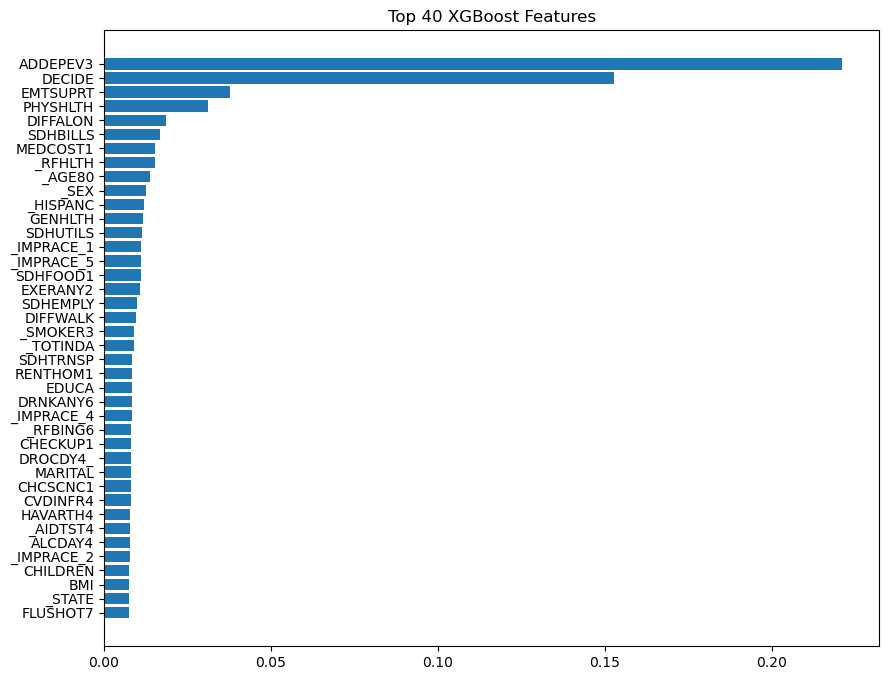

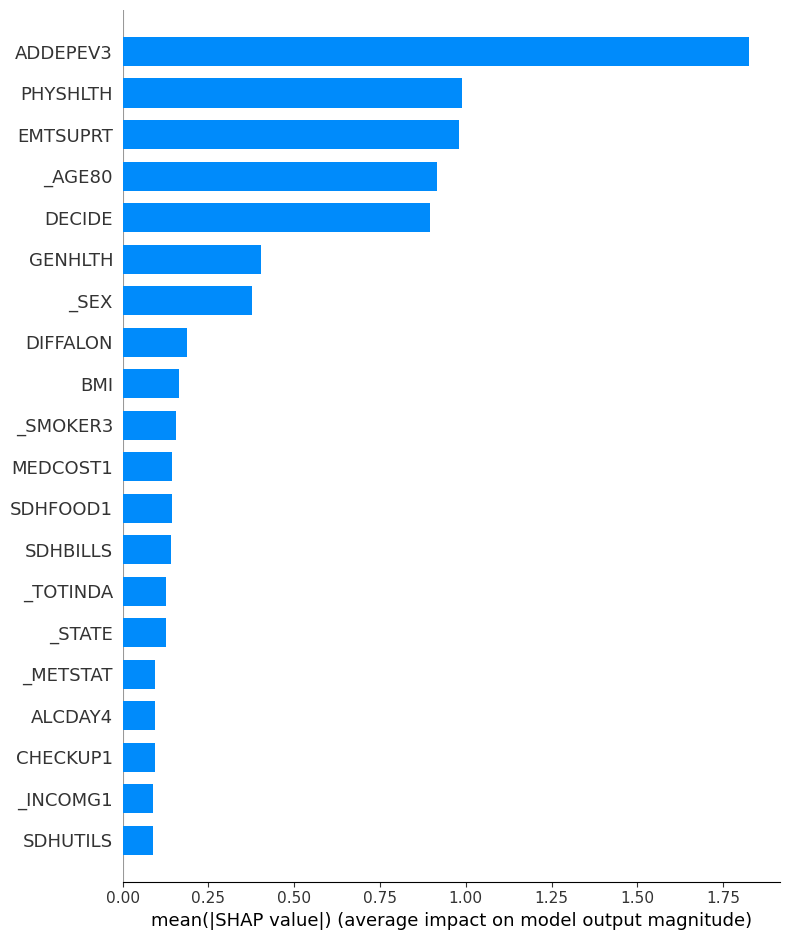

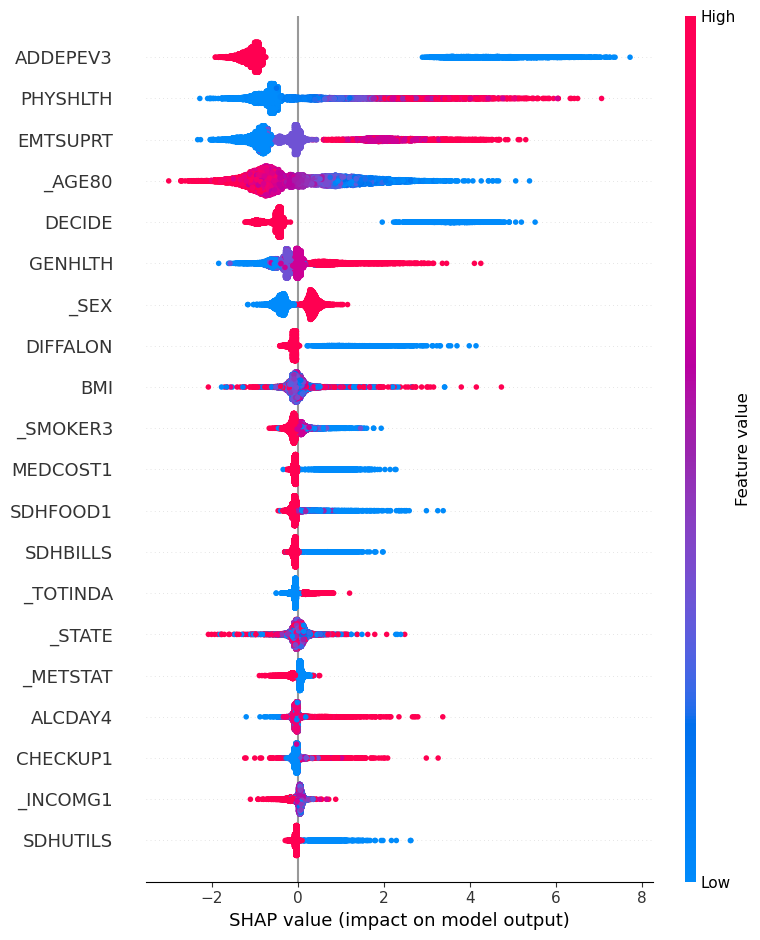


Saved: BRFSS_40-feature_importance_target-MENTHLTH.csv

       feature      SHAP       XGB
0     ADDEPEV3  1.824856  0.221103
1     PHYSHLTH  0.990325  0.031037
2     EMTSUPRT  0.981640  0.037597
3       _AGE80  0.917334  0.013806
4       DECIDE  0.896265  0.152717
5      GENHLTH  0.401745  0.011536
6         _SEX  0.375723  0.012430
7     DIFFALON  0.188500  0.018442
8          BMI  0.164242  0.007522
9     _SMOKER3  0.155190  0.009052
10    MEDCOST1  0.143675  0.015383
11    SDHFOOD1  0.143371  0.010912
12    SDHBILLS  0.141592  0.016858
13    _TOTINDA  0.125146  0.009004
14      _STATE  0.124980  0.007502
15    _METSTAT  0.095450  0.006679
16     ALCDAY4  0.093779  0.007713
17    CHECKUP1  0.093089  0.007984
18    _INCOMG1  0.089654  0.007280
19    SDHUTILS  0.088034  0.011240
20     MARITAL  0.086332  0.007939
21    DIFFWALK  0.078517  0.009413
22       EDUCA  0.076011  0.008423
23     INCOME3  0.075793  0.006970
24    SDHEMPLY  0.074629  0.009742
25    RENTHOM1  0.070726  0.00846

In [14]:
# ============================================================
# BRFSS Feature Importance using XGBoost
# Target: MENTHLTH
# ============================================================

print(f"Feature importance for target {target}")

# ============================================================
# Train Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ============================================================
# Train XGBoost
# ============================================================

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

# ============================================================
# Evaluate
# ============================================================

preds = model.predict(
    X_test
)

print()
print("MAE :", mean_absolute_error(y_test, preds))
print("R2  :", r2_score(y_test, preds))

# ============================================================
# XGBoost Native Importance
# ============================================================

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print()
print(f"Top {n_important_features} Features")
print(
    importance.head(n_important_features)
)

# ============================================================
# Plot Top Features
# ============================================================

top = importance.head(n_important_features)

plt.figure(figsize=(10,8))

plt.barh(
    top["feature"],
    top["importance"]
)

plt.gca().invert_yaxis()

plt.title(
    f"Top {n_important_features} XGBoost Features"
)

plt.show()

# ============================================================
# SHAP Explainability
# ============================================================

explainer = shap.TreeExplainer(
    model
)

# use sample for speed

sample = X_train.sample(
    min(10000, len(X_train)),
    random_state=42
)

shap_values = explainer.shap_values(
    sample
)

# ============================================================
# SHAP Global Importance
# ============================================================

shap.summary_plot(
    shap_values,
    sample,
    plot_type="bar"
)

# ============================================================
# SHAP Detailed Summary
# ============================================================

shap.summary_plot(
    shap_values,
    sample
)

# ============================================================
# Save Ranked Features
# ============================================================

shap_importance = pd.DataFrame({

    "feature": sample.columns,

    "shap_importance":
        np.abs(shap_values).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "shap_importance",
    ascending=False
)


# Merge on 'feature', keep all unique features from both DataFrames
merged = pd.merge(
    shap_importance,   # shap_importance
    importance,        # importance (XGBoost, etc.)
    on='feature',
    how='outer',       # keeps all unique features from both
    suffixes=('_shap', '_importance')
)

# Rename columns for clarity
merged = merged.rename(columns={
    "shap_importance": "SHAP",
    "importance": "XGB"
})

# Sort by SHAP importance (descending), NaNs last
merged = merged.sort_values('SHAP', ascending=False, na_position='last').reset_index(drop=True)


merged.to_csv(
    f"BRFSS_{n_important_features}-feature_importance_target-{target}.csv",
    index=False
)

print()
print(f"Saved: BRFSS_{n_important_features}-feature_importance_target-{target}.csv")

print()
print(merged.head(n_important_features))

In [15]:
xgb_important_feature_names = list(importance.feature[:n_important_features])
print("XGBoost")
for i, feature_name in enumerate(xgb_important_feature_names, 1):
    if feature_name.count("_") > 1:
        feature_name = "_" + feature_name.split("_")[1]
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

shap_important_feature_names = list(shap_importance.feature[:n_important_features])
print("SHAP")
for i, feature_name in enumerate(shap_important_feature_names, 1):
    if feature_name.count("_") > 1:
        feature_name = "_" + feature_name.split("_")[1]
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

df_combined = pd.concat([X, y], axis=1)

# Save preprocessed data with important features
df_preprocessed_with_feature_importance = df_combined.loc[:, shap_important_feature_names + [target]]
df_preprocessed_with_feature_importance.to_csv(
                    f"data/preprocessed/{n_years}-years_{len(df_preprocessed_with_feature_importance)}-samples_{n_important_features}-features_{target}-target.csv",
                    index=False
)

MENTHLTH_top_features = shap_important_feature_names.copy()
print(MENTHLTH_top_features)

XGBoost
1 	 ADDEPEV3 	 (ever told) you had a depressive disorder
2 	 DECIDE 	 Difficulty concentrating or remembering
3 	 EMTSUPRT 	 How often get emotional support needed
4 	 PHYSHLTH 	 Number of days physical health not good
5 	 DIFFALON 	 Difficulty doing errands alone
6 	 SDHBILLS 	 Were you not able to pay your bills?
7 	 MEDCOST1 	 Could not afford to see doctor
8 	 _RFHLTH 	 Adults with good or better health
9 	 _AGE80 	 Imputed age value collapsed above 80
10 	 _SEX 	 Calculated sex variable
11 	 _HISPANC 	 Hispanic, latino/a, or spanish origin calculated variable
12 	 GENHLTH 	 General health
13 	 SDHUTILS 	 Were you not able to pay utility bills or threatened to lose service?
14 	 _IMPRACE 	 Imputed race/ethnicity value
15 	 _IMPRACE 	 Imputed race/ethnicity value
16 	 SDHFOOD1 	 How often did the food that you bought not last, and you didnt have money to get more?
17 	 EXERANY2 	 Exercise in past 30 days
18 	 SDHEMPLY 	 Have you lost employment or had hours reduced?
19 	 DI

## LSATISFY

Feature importance for target LSATISFY

MAE : 0.41571259804815053
R2  : 0.33459030446219973

Top 40 Features
       feature  importance
51    EMTSUPRT    0.164132
49     _RFHLTH    0.083659
31    ADDEPEV3    0.072948
37      DECIDE    0.072506
0      GENHLTH    0.056532
39     MARITAL    0.028020
52    SDHTRNSP    0.023620
58    DIFFALON    0.018667
29    RENTHOM1    0.016060
63    SDHBILLS    0.014322
19    SDHFOOD1    0.013544
69  _IMPRACE_5    0.013107
46    DIFFWALK    0.012521
36    PHYSHLTH    0.011255
40    SDHEMPLY    0.011159
65  _IMPRACE_1    0.010476
12    _HISPANC    0.010380
28    MEDCOST1    0.010330
26    _TOTINDA    0.009672
45    DIFFDRES    0.008990
56    EXERANY2    0.008718
6       _AGE80    0.008700
61    CHILDREN    0.008576
33    SDHUTILS    0.008362
15        _SEX    0.008276
57       EDUCA    0.008208
50    _INCOMG1    0.008144
8      INCOME3    0.007960
22    CHECKUP1    0.007842
34    _SMOKER3    0.007838
47    CVDSTRK3    0.007816
25    CVDINFR4    0.007526


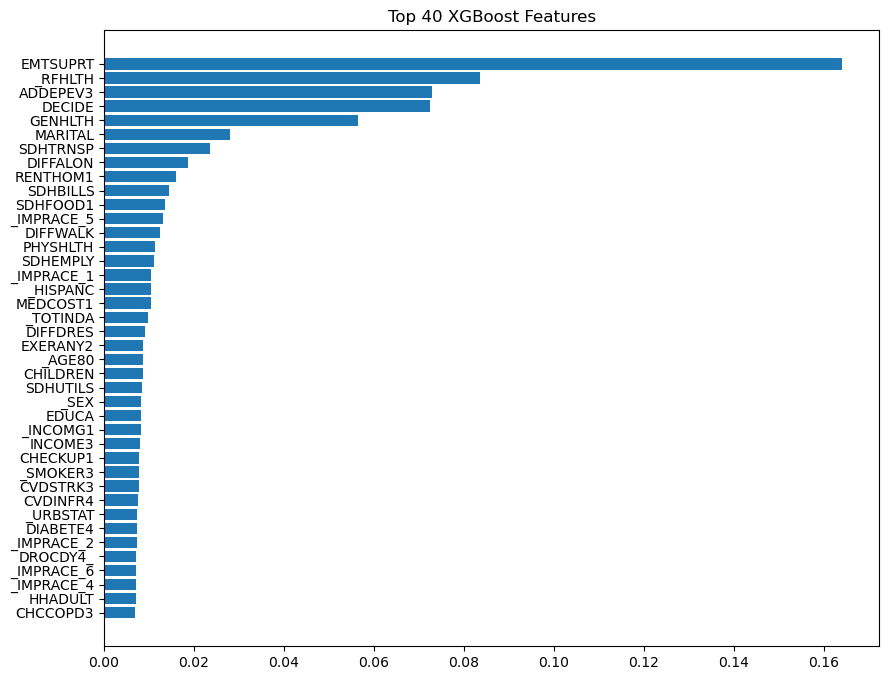

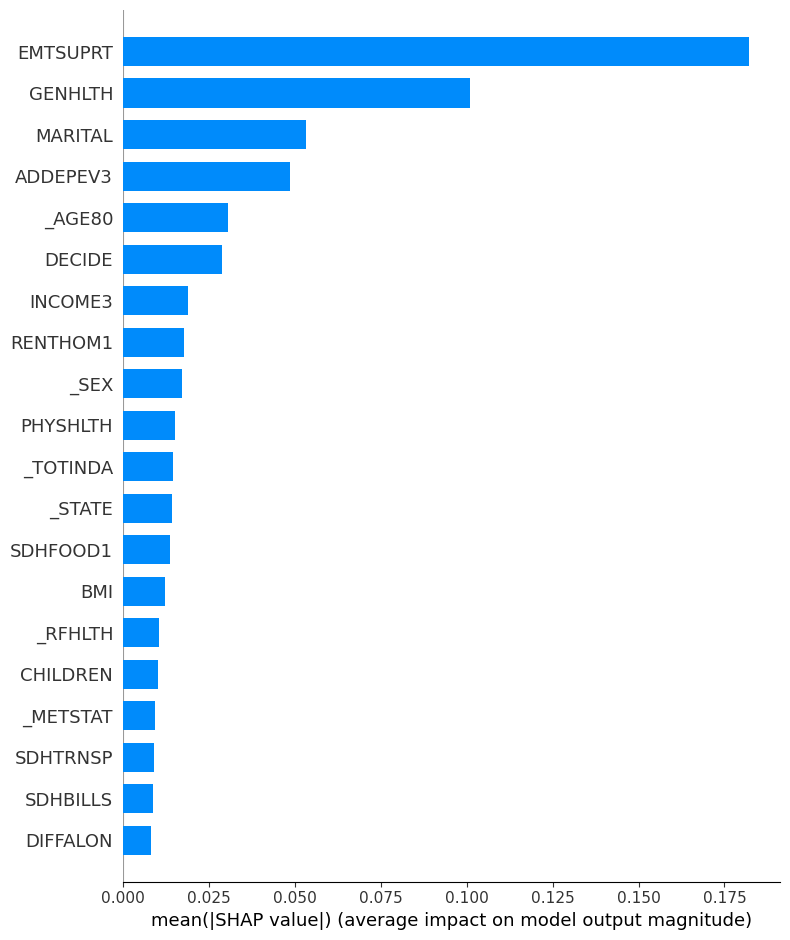

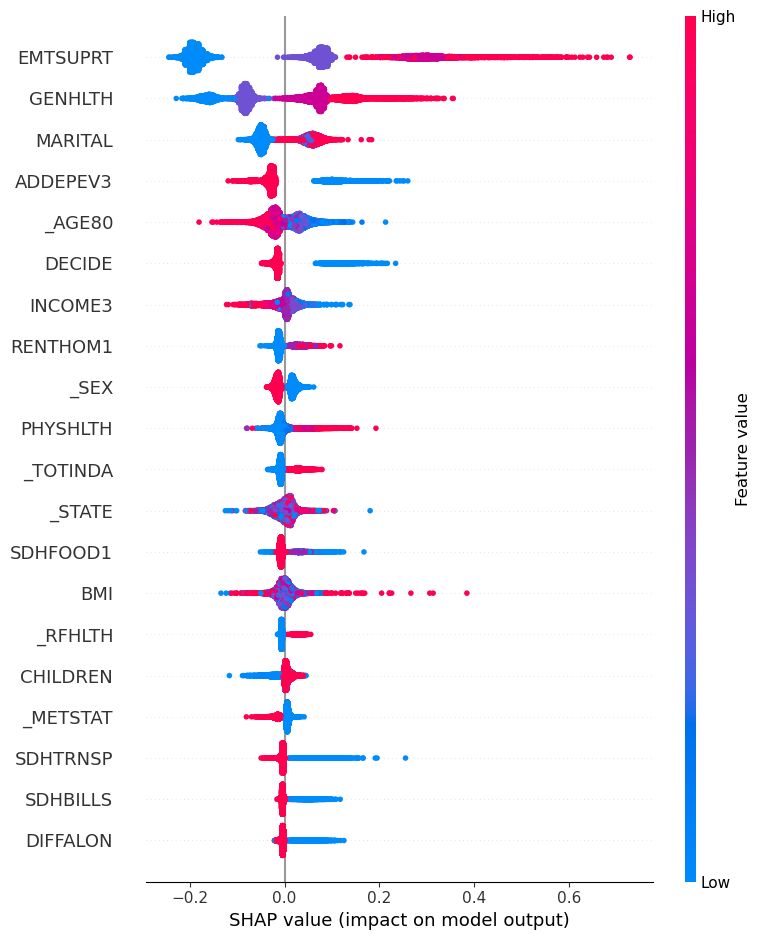


Saved: BRFSS_40-feature_importance_target-LSATISFY.csv

       feature      SHAP       XGB
0     EMTSUPRT  0.182054  0.164132
1      GENHLTH  0.101095  0.056532
2      MARITAL  0.053302  0.028020
3     ADDEPEV3  0.048624  0.072948
4       _AGE80  0.030544  0.008700
5       DECIDE  0.028793  0.072506
6      INCOME3  0.019007  0.007960
7     RENTHOM1  0.017751  0.016060
8         _SEX  0.017169  0.008276
9     PHYSHLTH  0.015273  0.011255
10    _TOTINDA  0.014506  0.009672
11      _STATE  0.014440  0.006665
12    SDHFOOD1  0.013621  0.013544
13         BMI  0.012343  0.006886
14     _RFHLTH  0.010618  0.083659
15    CHILDREN  0.010240  0.008576
16    _METSTAT  0.009412  0.006413
17    SDHTRNSP  0.008960  0.023620
18    SDHBILLS  0.008826  0.014322
19    DIFFALON  0.008110  0.018667
20       EDUCA  0.007784  0.008208
21    CHECKUP1  0.007684  0.007842
22    _HISPANC  0.007567  0.010380
23    SDHEMPLY  0.007396  0.011159
24    DIFFWALK  0.006905  0.012521
25     EMPLOY1  0.006687  0.00589

In [16]:
# ============================================================
# BRFSS Feature Importance using XGBoost
# Target: LSATISFY
# ============================================================

print(f"Feature importance for target {target_}")

# ============================================================
# Train Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_,
    test_size=0.20,
    random_state=42
)

# ============================================================
# Train XGBoost
# ============================================================

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

# ============================================================
# Evaluate
# ============================================================

preds = model.predict(
    X_test
)

print()
print("MAE :", mean_absolute_error(y_test, preds))
print("R2  :", r2_score(y_test, preds))

# ============================================================
# XGBoost Native Importance
# ============================================================

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print()
print(f"Top {n_important_features} Features")
print(
    importance.head(n_important_features)
)

# ============================================================
# Plot Top Features
# ============================================================

top = importance.head(n_important_features)

plt.figure(figsize=(10,8))

plt.barh(
    top["feature"],
    top["importance"]
)

plt.gca().invert_yaxis()

plt.title(
    f"Top {n_important_features} XGBoost Features"
)

plt.show()

# ============================================================
# SHAP Explainability
# ============================================================

explainer = shap.TreeExplainer(
    model
)

# use sample for speed

sample = X_train.sample(
    min(10000, len(X_train)),
    random_state=42
)

shap_values = explainer.shap_values(
    sample
)

# ============================================================
# SHAP Global Importance
# ============================================================

shap.summary_plot(
    shap_values,
    sample,
    plot_type="bar"
)

# ============================================================
# SHAP Detailed Summary
# ============================================================

shap.summary_plot(
    shap_values,
    sample
)

# ============================================================
# Save Ranked Features
# ============================================================

shap_importance = pd.DataFrame({

    "feature": sample.columns,

    "shap_importance":
        np.abs(shap_values).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "shap_importance",
    ascending=False
)

# Merge on 'feature', keep all unique features from both DataFrames
merged = pd.merge(
    shap_importance,   # shap_importance
    importance,        # importance (XGBoost, etc.)
    on='feature',
    how='outer',       # keeps all unique features from both
    suffixes=('_shap', '_importance')
)

# Rename columns for clarity
merged = merged.rename(columns={
    "shap_importance": "SHAP",
    "importance": "XGB"
})

# Sort by SHAP importance (descending), NaNs last
merged = merged.sort_values('SHAP', ascending=False, na_position='last').reset_index(drop=True)

merged.to_csv(
    f"BRFSS_{n_important_features}-feature_importance_target-{target_}.csv",
    index=False
)

print()
print(f"Saved: BRFSS_{n_important_features}-feature_importance_target-{target_}.csv")

print()
print(merged.head(n_important_features))

In [17]:
xgb_important_feature_names = list(importance.feature[:n_important_features])
print("XGBoost")
for i, feature_name in enumerate(xgb_important_feature_names, 1):
    if feature_name.count("_") > 1:
        feature_name = "_" + feature_name.split("_")[1]
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

shap_important_feature_names = list(shap_importance.feature[:n_important_features])
print("SHAP")
for i, feature_name in enumerate(shap_important_feature_names, 1):
    if feature_name.count("_") > 1:
        feature_name = "_" + feature_name.split("_")[1]
    print(i, "\t", feature_name, "\t", feature_details[feature_name]["desc"])

df_combined = pd.concat([X, y_], axis=1)

# Save preprocessed data with important features
df_preprocessed_with_feature_importance = df_combined.loc[:, shap_important_feature_names + [target_]]
df_preprocessed_with_feature_importance.to_csv(
                    f"data/preprocessed/{n_years}-years_{len(df_preprocessed_with_feature_importance)}-samples_{n_important_features}-features_{target_}-target.csv",
                    index=False
)

LSATISFY_top_features = shap_important_feature_names.copy()
print(LSATISFY_top_features)

XGBoost
1 	 EMTSUPRT 	 How often get emotional support needed
2 	 _RFHLTH 	 Adults with good or better health
3 	 ADDEPEV3 	 (ever told) you had a depressive disorder
4 	 DECIDE 	 Difficulty concentrating or remembering
5 	 GENHLTH 	 General health
6 	 MARITAL 	 Marital status
7 	 SDHTRNSP 	 Has a lack of reliable transportation kept you from appointments, meetings, work, or getting things needed
8 	 DIFFALON 	 Difficulty doing errands alone
9 	 RENTHOM1 	 Own or rent home
10 	 SDHBILLS 	 Were you not able to pay your bills?
11 	 SDHFOOD1 	 How often did the food that you bought not last, and you didnt have money to get more?
12 	 _IMPRACE 	 Imputed race/ethnicity value
13 	 DIFFWALK 	 Difficulty walking or climbing stairs
14 	 PHYSHLTH 	 Number of days physical health not good
15 	 SDHEMPLY 	 Have you lost employment or had hours reduced?
16 	 _IMPRACE 	 Imputed race/ethnicity value
17 	 _HISPANC 	 Hispanic, latino/a, or spanish origin calculated variable
18 	 MEDCOST1 	 Could not af

---

# Data Visualization

In [18]:
# Create plots directory if it doesn't exist
os.makedirs("plots", exist_ok=True)

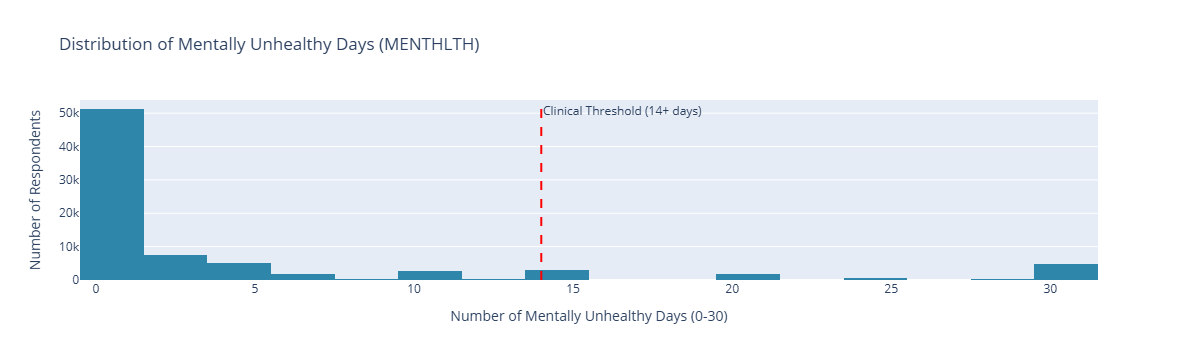

In [19]:
# ============================================================
# 1. Target Distribution (MENTHLTH)
# ============================================================
fig1 = px.histogram(
    y,
    nbins=30,
    title="Distribution of Mentally Unhealthy Days (MENTHLTH)",
    labels={"value": "Number of Days", "count": "Frequency"},
    color_discrete_sequence=["#2E86AB"]
)
fig1.add_vline(x=14, line_dash="dash", line_color="red", 
               annotation_text="Clinical Threshold (14+ days)")
fig1.update_layout(
    xaxis_title="Number of Mentally Unhealthy Days (0-30)",
    yaxis_title="Number of Respondents",
    showlegend=False
)
fig1.write_html(f"plots/1_target_distribution_{target}.html")
fig1.show()

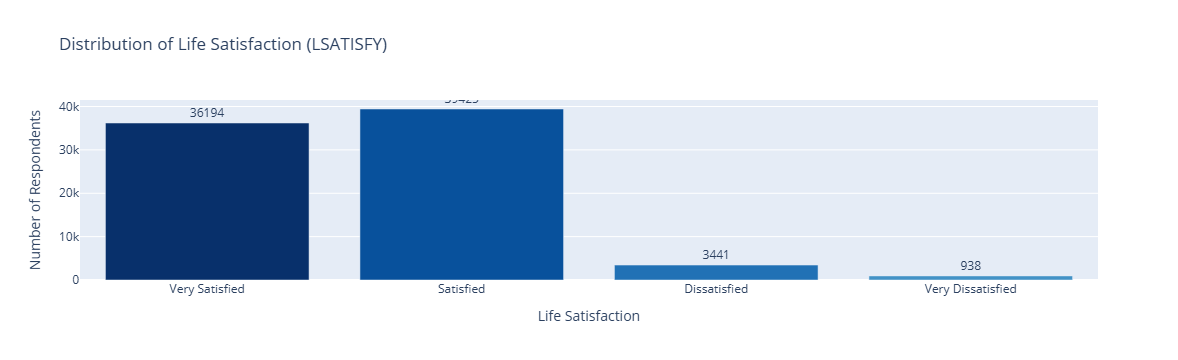

In [20]:
# ============================================================
# 2. Target Distribution (LSATISFY)
# ============================================================

# Define labels for the satisfaction levels
satisfaction_labels = {
    1: "Very Satisfied",
    2: "Satisfied",
    3: "Dissatisfied",
    4: "Very Dissatisfied"
}

# Create a DataFrame for plotting
df_plot = pd.DataFrame({target: y_})
df_plot['Label'] = df_plot[target].map(satisfaction_labels)

# Count the occurrences
counts = df_plot['Label'].value_counts().reset_index()
counts.columns = ['Satisfaction Level', 'Count']

# Ensure correct order (Very Satisfied -> Very Dissatisfied)
category_order = ["Very Satisfied", "Satisfied", "Dissatisfied", "Very Dissatisfied"]
counts['Satisfaction Level'] = pd.Categorical(counts['Satisfaction Level'], categories=category_order, ordered=True)
counts = counts.sort_values('Satisfaction Level')

fig2 = px.bar(    
    counts,
    x='Satisfaction Level',
    y='Count',
    title="Distribution of Life Satisfaction (LSATISFY)",
    labels={'Count': 'Number of Respondents', 'Satisfaction Level': 'Life Satisfaction'},
    color='Satisfaction Level',
    color_discrete_sequence=px.colors.sequential.Blues_r,
    text='Count'
)

fig2.update_traces(textposition='outside')
fig2.update_layout(
    xaxis_title="Life Satisfaction",
    yaxis_title="Number of Respondents",
    showlegend=False,
    xaxis={'categoryorder': 'array', 'categoryarray': category_order}
)

fig2.write_html(f"plots/2_target_distribution_{target_}.html")
fig2.show()

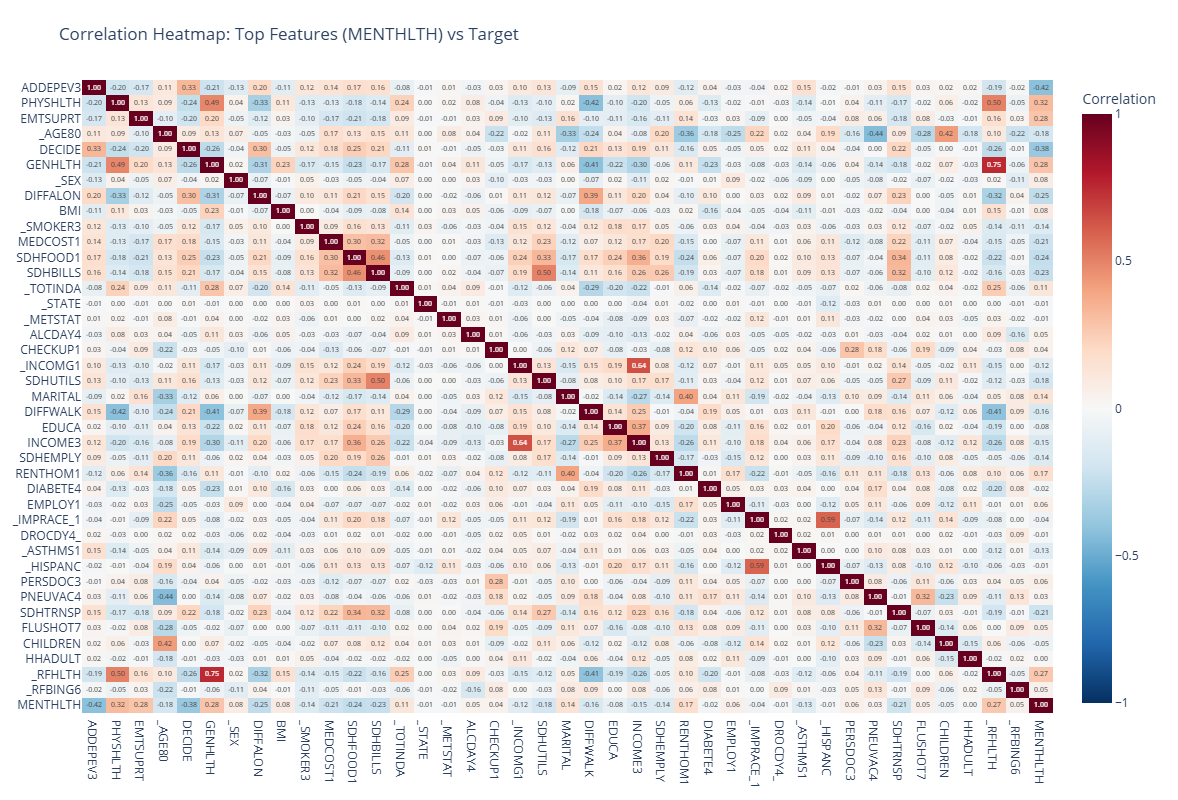

In [21]:
# ============================================================
# 3.a Correlation Heatmap of Top Features [MENTHLTH] -- TOP 40
# ============================================================

top_features = MENTHLTH_top_features[:40]
corr_data = X[top_features].copy()
corr_data[target] = y.values
corr_matrix = corr_data.corr()

fig3a = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title=f"Correlation Heatmap: Top Features ({target}) vs Target",
    labels={"color": "Correlation", "variable": "", "y": ""},
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)

# Make it responsive and take up full available space
fig3a.update_layout(
    autosize=True,          # Automatically size to container
    height=800,             # You can adjust this as needed
    width=None,             # Let it stretch horizontally
    font=dict(size=12),     # Slightly larger font for readability
    margin=dict(l=50, r=50, t=80, b=50)  # Reduce margins to maximize plot area
)

# Show with responsive config
fig3a.show(config={'responsive': True})

# Save HTML (still with responsive layout)
fig3a.write_html(
    f"plots/3-a_correlation_heatmap_{target}.html",
    include_plotlyjs='cdn',
    config={'responsive': True}
)

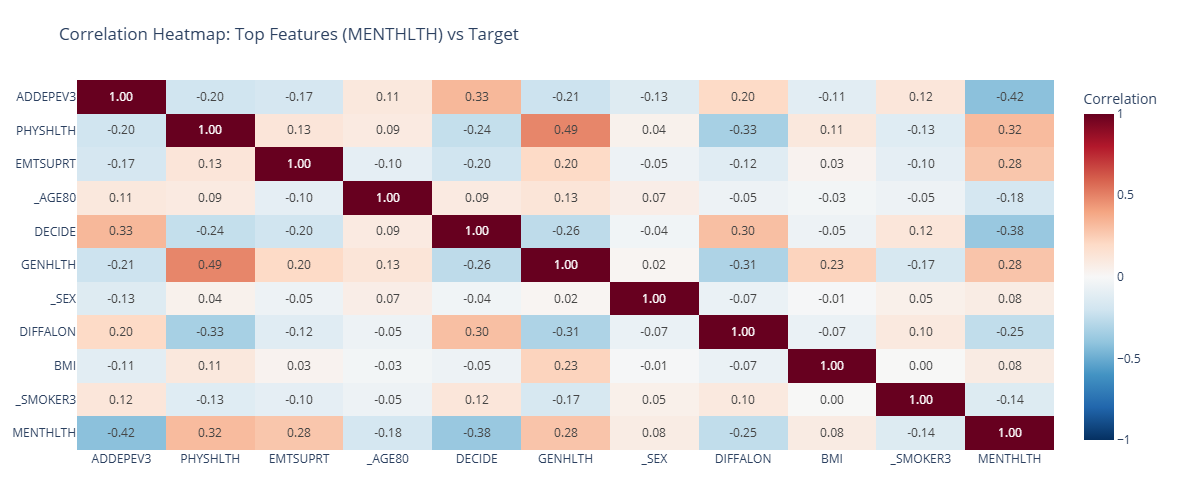

In [22]:
# ============================================================
# 3.b Correlation Heatmap of Top Features [MENTHLTH] -- TOP 10
# ============================================================

top_features = MENTHLTH_top_features[:10]
corr_data = X[top_features].copy()
corr_data[target] = y.values
corr_matrix = corr_data.corr()

fig3b = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title=f"Correlation Heatmap: Top Features ({target}) vs Target",
    labels={"color": "Correlation", "variable": "", "y": ""},
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)

# Make it responsive and take up full available space
fig3b.update_layout(
    autosize=False,          # Automatically size to container
    height=500,             # You can adjust this as needed
    width=None,             # Let it stretch horizontally
    font=dict(size=12),     # Slightly larger font for readability
    margin=dict(l=50, r=50, t=80, b=50)  # Reduce margins to maximize plot area
)

# Show with responsive config
fig3b.show(config={'responsive': True})

# Save HTML (still with responsive layout)
fig3b.write_html(
    f"plots/3-b_correlation_heatmap_{target}.html",
    include_plotlyjs='cdn',
    config={'responsive': True}
)

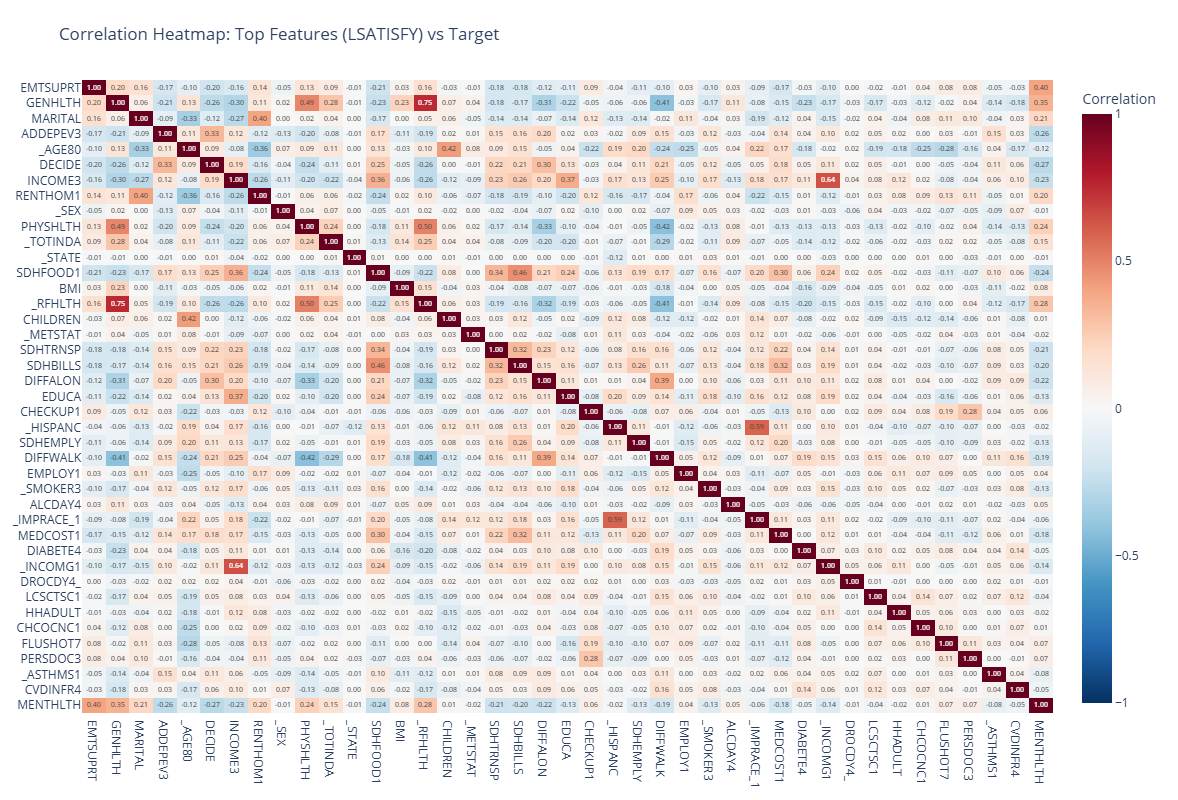

In [23]:
# ============================================================
# 4.a Correlation Heatmap of Top Features [LSATISFY] -- TOP 40
# ============================================================

# Use the top features identified for LSATISFY
top_features = LSATISFY_top_features[:40]
corr_data = X[top_features].copy()
corr_data[target] = y_.values
corr_matrix = corr_data.corr()

fig4a = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title=f"Correlation Heatmap: Top Features ({target_}) vs Target",
    labels={"color": "Correlation", "variable": "", "y": ""},
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)

# Make it responsive and take up full available space
fig4a.update_layout(
    autosize=True,          # Automatically size to container
    height=800,             # You can adjust this as needed
    width=None,             # Let it stretch horizontally
    font=dict(size=12),     # Slightly larger font for readability
    margin=dict(l=50, r=50, t=80, b=50)  # Reduce margins to maximize plot area
)

# Show with responsive config
fig4a.show(config={'responsive': True})

# Save HTML (still with responsive layout)
fig4a.write_html(
    f"plots/4-a_correlation_heatmap_{target_}.html",
    include_plotlyjs='cdn',
    config={'responsive': True}
)

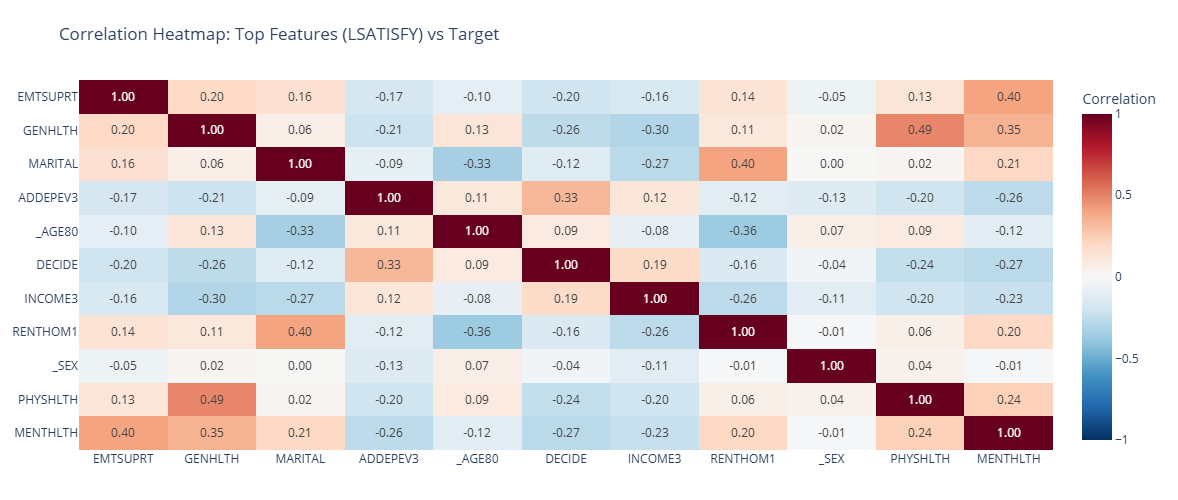

In [24]:
# ============================================================
# 4.b Correlation Heatmap of Top Features [LSATISFY] -- TOP 10
# ============================================================

# Use the top features identified for LSATISFY
top_features = LSATISFY_top_features[:10]
corr_data = X[top_features].copy()
corr_data[target] = y_.values
corr_matrix = corr_data.corr()

fig4b = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    title=f"Correlation Heatmap: Top Features ({target_}) vs Target",
    labels={"color": "Correlation", "variable": "", "y": ""},
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1
)

# Make it responsive and take up full available space
fig4b.update_layout(
    autosize=False,          # Automatically size to container
    height=500,             # You can adjust this as needed
    width=None,             # Let it stretch horizontally
    font=dict(size=12),     # Slightly larger font for readability
    margin=dict(l=50, r=50, t=80, b=50)  # Reduce margins to maximize plot area
)

# Show with responsive config
fig4b.show(config={'responsive': True})

# Save HTML (still with responsive layout)
fig4b.write_html(
    f"plots/4-b_correlation_heatmap_{target_}.html",
    include_plotlyjs='cdn',
    config={'responsive': True}
)

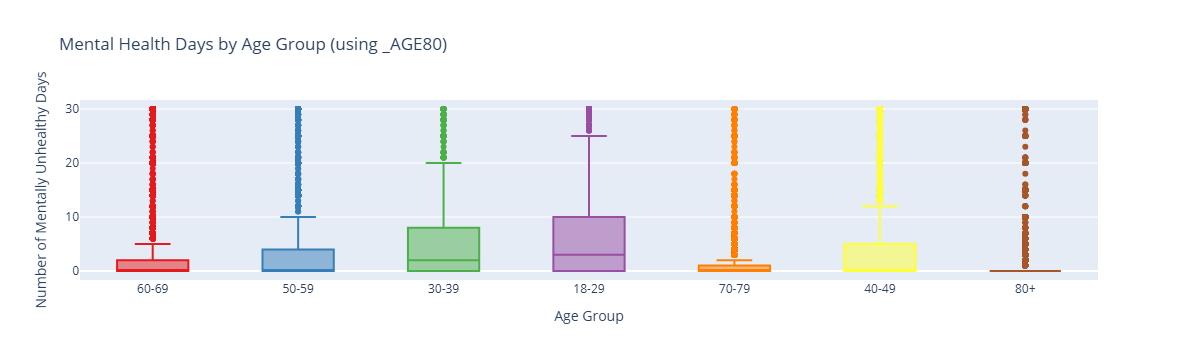

In [25]:
# ============================================================
# 5. Age Distribution of Mental Health Days (using _AGE80)
# ============================================================

# Define age bins for _AGE80 (collapsed above 80, but we'll create groups)
# _AGE80 ranges from 18 to 80+ (values above 80 are coded as 80)
# We'll create bins: 18-29, 30-39, 40-49, 50-59, 60-69, 70-79, 80+
age_bins = [18, 30, 40, 50, 60, 70, 80, 100]
age_labels = ["18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

# Create a DataFrame with target and _AGE80
df_age = pd.DataFrame({
    target: y,
    "_AGE80": X["_AGE80"]
})

# Create age group column
df_age["AGE_GROUP"] = pd.cut(
    df_age["_AGE80"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Remove any rows with missing age group (if any)
df_age = df_age.dropna(subset=["AGE_GROUP"])

# Create boxplot
fig5 = px.box(
    df_age,
    x="AGE_GROUP",
    y=target,
    title=f"Mental Health Days by Age Group (using _AGE80)",
    labels={"AGE_GROUP": "Age Group", target: "Mentally Unhealthy Days"},
    color="AGE_GROUP",
    color_discrete_sequence=px.colors.qualitative.Set1
)

fig5.update_layout(
    xaxis_title="Age Group",
    yaxis_title="Number of Mentally Unhealthy Days",
    showlegend=False
)

fig5.write_html(f"plots/5_age_vs_menthealth_{target}.html")
fig5.show()

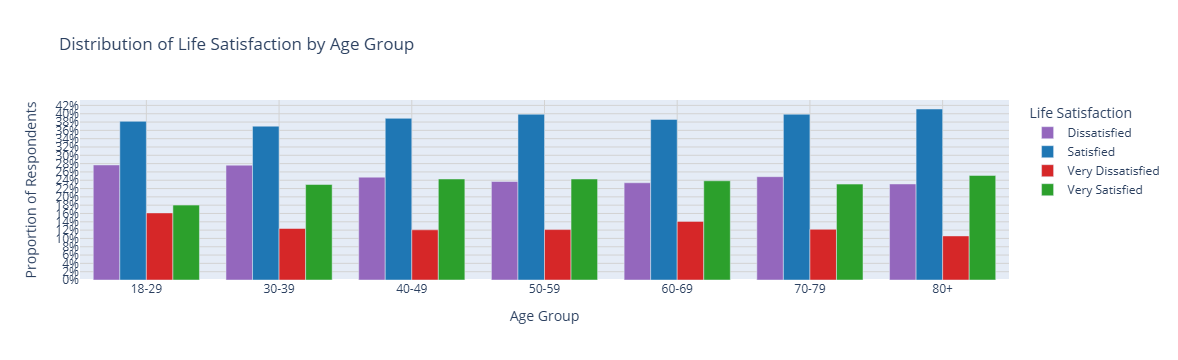

In [26]:
# ============================================================
# 6. Age Distribution of Life Satisfaction (using _AGE80)
# ============================================================

# ----- 1. Prepare the data -----

# Define age bins for _AGE80 (collapsed above 80)
age_bins = [18, 30, 40, 50, 60, 70, 80, 100]
age_labels = ["18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

# Define labels for LSATISFY
satisfaction_labels = {
    1: "Very Satisfied",
    2: "Satisfied",
    3: "Dissatisfied",
    4: "Very Dissatisfied"
}

# Custom color mapping for satisfaction levels
color_map = {
    "Very Satisfied": "#2CA02C",    # Green
    "Satisfied": "#1F77B4",         # Blue
    "Dissatisfied": "#9467BD",      # Purple
    "Very Dissatisfied": "#D62728"  # Red
}

# Create a DataFrame with target and _AGE80
df_age = pd.DataFrame({
    target: y,                       # target is 'LSATISFY'
    "_AGE80": X["_AGE80"]
})

# Create age group column
df_age["AGE_GROUP"] = pd.cut(
    df_age["_AGE80"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Map numeric target to labels
df_age["SATISFACTION_LABEL"] = df_age[target].map(satisfaction_labels)

# Remove rows with missing age group or satisfaction label
df_age = df_age.dropna(subset=["AGE_GROUP", "SATISFACTION_LABEL"])

# ----- 2. Create crosstab of satisfaction levels by age group -----

satisfaction_by_age = pd.crosstab(
    df_age["AGE_GROUP"],
    df_age["SATISFACTION_LABEL"],
    normalize='index'
).reset_index().melt(
    id_vars=["AGE_GROUP"],
    var_name="Satisfaction Level",
    value_name="Proportion"
)

# ----- 3. Create the bar chart with custom colors -----

fig6 = px.bar(
    satisfaction_by_age,
    x="AGE_GROUP",
    y="Proportion",
    color="Satisfaction Level",
    title="Distribution of Life Satisfaction by Age Group",
    labels={"AGE_GROUP": "Age Group", "Proportion": "Proportion of Respondents"},
    color_discrete_map=color_map,   # Apply custom colors
    barmode="group"
)

fig6.update_layout(
    xaxis_title="Age Group",
    yaxis_title="Proportion of Respondents",
    xaxis=dict(showgrid=True, gridcolor='lightgray', gridwidth=1),
    yaxis=dict(
        showgrid=True,
        gridcolor='lightgray',
        gridwidth=1,
        tickformat=".0%",
        dtick=0.02
    ),
    legend_title="Life Satisfaction"
)

fig6.write_html(f"plots/6_age_vs_lsatisify_{target}.html")
fig6.show()

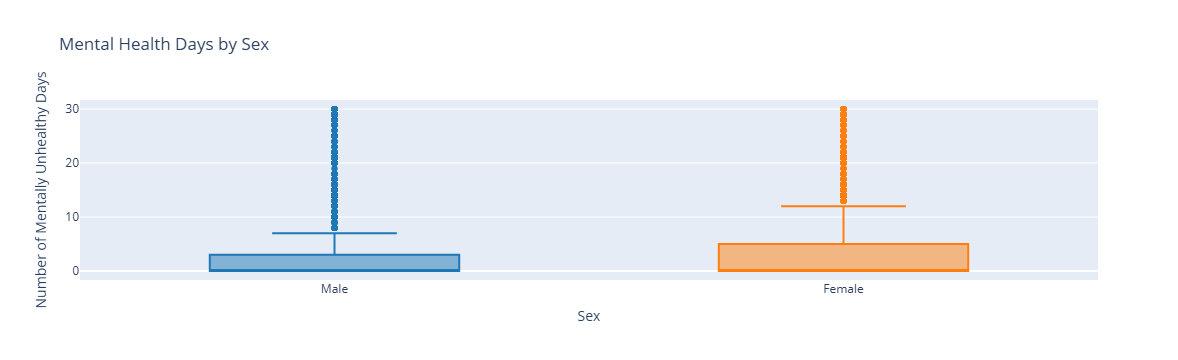

In [27]:
# ============================================================
# 7. Sex Comparison of Mental Health Days
# ============================================================
if "_SEX" in X:
    sex_labels = {1: "Male", 2: "Female"}
    df_sex = pd.DataFrame({
        target: y,
        "SEX": X["_SEX"]
    })
    df_sex["SEX_LABEL"] = df_sex["SEX"].map(sex_labels)
    
    fig7 = px.box(
        df_sex,
        x="SEX_LABEL",
        y=target,
        title="Mental Health Days by Sex",
        labels={"SEX_LABEL": "Sex", target: "Mentally Unhealthy Days"},
        color="SEX_LABEL",
        color_discrete_sequence=["#1F77B4", "#FF7F0E"]
    )
    fig7.update_layout(
        xaxis_title="Sex",
        yaxis_title="Number of Mentally Unhealthy Days",
        showlegend=False
    )
    fig7.write_html(f"plots/7_sex_vs_menthealth_{target}.html")
    fig7.show()

In [28]:
# ============================================================
# 8. Sex Comparison of Life Satisfaction (All 4 States)
# ============================================================
if "_SEX" in X.columns:
    # Define labels
    sex_labels = {1: "Male", 2: "Female"}
    satisfaction_labels = {
        1: "Very Satisfied",
        2: "Satisfied",
        3: "Dissatisfied",
        4: "Very Dissatisfied"
    }
    
    # Custom color mapping for satisfaction levels
    color_map = {
        "Very Satisfied": "#2CA02C",    # Green
        "Satisfied": "#1F77B4",         # Blue
        "Dissatisfied": "#9467BD",      # Purple
        "Very Dissatisfied": "#D62728"  # Red
    }
    
    # Create DataFrame
    df_sex = pd.DataFrame({
        target: y,
        "SEX": X["_SEX"]
    })
    df_sex["SEX_LABEL"] = df_sex["SEX"].map(sex_labels)
    df_sex["SATISFACTION_LABEL"] = df_sex[target].map(satisfaction_labels)
    
    # Drop missing values
    df_sex = df_sex.dropna(subset=["SEX_LABEL", "SATISFACTION_LABEL"])
    
    # Create crosstab: satisfaction levels by sex
    sex_satisfaction = pd.crosstab(
        df_sex["SEX_LABEL"],
        df_sex["SATISFACTION_LABEL"],
        normalize='index'
    ).reset_index().melt(
        id_vars=["SEX_LABEL"],
        var_name="Satisfaction Level",
        value_name="Proportion"
    )
    
    # Create grouped bar chart
    fig8 = px.bar(
        sex_satisfaction,
        x="SEX_LABEL",
        y="Proportion",
        color="Satisfaction Level",
        title="Life Satisfaction by Sex",
        labels={"SEX_LABEL": "Sex", "Proportion": "Proportion of Respondents"},
        color_discrete_map=color_map,  # Use custom colors
        barmode="group"
    )
    
    fig8.update_layout(
        xaxis_title="Sex",
        yaxis_title="Proportion of Respondents",
        xaxis=dict(showgrid=True, gridcolor='lightgray', gridwidth=1),
        yaxis=dict(
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=1,
            tickformat=".0%",
            dtick=0.05
        ),
        legend_title="Life Satisfaction"
    )
    
    fig8.write_html(f"plots/8_sex_vs_lsatisify_{target}.html")
    fig8.show()

In [29]:
# ============================================================
# Mental Health Days by Income - Strip/Swarm Plot (Alternative)
# ============================================================

if "_INCOMG1" in X.columns:

    # ---- 1. Prepare data ----
    income_labels = {
        1: "Less than $15,000",
        2: "$15K–$24,999",
        3: "$25K–$34,999",
        4: "$35K–$49,999",
        5: "$50K–$99,999",
        6: "$100K–$199,999",
        7: "$200,000 or more",
        9: "Don't know / Refused"
    }

    df_income = pd.DataFrame({
        target: y,
        "_INCOMG1": X["_INCOMG1"]
    }).dropna(subset=["_INCOMG1", target])

    # Ensure target is numeric
    if not pd.api.types.is_numeric_dtype(df_income[target]):
        df_income[target] = pd.to_numeric(df_income[target], errors='coerce')
        df_income = df_income.dropna(subset=[target])

    # Map income codes to labels
    df_income["INCOME_LABEL"] = df_income["_INCOMG1"].map(income_labels)
    df_income = df_income[df_income["INCOME_LABEL"].notna()]

    # Remove "Don't know / Refused" for cleaner plot
    df_income = df_income[df_income["INCOME_LABEL"] != "Don't know / Refused"]

    # Set proper order
    income_order = [
        "Less than $15,000", "$15K–$24,999", "$25K–$34,999",
        "$35K–$49,999", "$50K–$99,999", "$100K–$199,999",
        "$200,000 or more"
    ]
    df_income["INCOME_LABEL"] = pd.Categorical(
        df_income["INCOME_LABEL"],
        categories=income_order,
        ordered=True
    )
    df_income = df_income.sort_values("INCOME_LABEL")

    # Check counts
    print("Counts per income category:")
    print(df_income["INCOME_LABEL"].value_counts().sort_index())

    # ---- 2. Alternative 1: Strip Plot ----
    fig_strip = px.strip(
        df_income,
        x="INCOME_LABEL",
        y=target,
        title="Mental Health Days by Household Income (Strip Plot)",
        labels={
            "INCOME_LABEL": "Annual Household Income",
            target: "Mentally Unhealthy Days (0–30)"
        },
        color="INCOME_LABEL",
        color_discrete_sequence=px.colors.sequential.Blues_r,
        stripmode="overlay"  # or "jitter"
    )

    fig_strip.update_layout(
        xaxis_title="Annual Household Income",
        yaxis_title="Number of Mentally Unhealthy Days (0–30)",
        xaxis=dict(tickangle=-15, showgrid=True, gridcolor='lightgray', gridwidth=1),
        yaxis=dict(showgrid=True, gridcolor='lightgray', gridwidth=1),
        showlegend=False,
        height=600
    )

    #fig_strip.write_html(f"plots/income_vs_menthealth_{target}_strip.html")
    #fig_strip.show()

    # ---- 3. Alternative 2: Violin Plot (shows distribution) ----
    fig_violin = px.violin(
        df_income,
        x="INCOME_LABEL",
        y=target,
        title="Mental Health Days by Household Income (Violin Plot)",
        labels={
            "INCOME_LABEL": "Annual Household Income",
            target: "Mentally Unhealthy Days (0–30)"
        },
        color="INCOME_LABEL",
        color_discrete_sequence=px.colors.sequential.Blues_r,
        box=True,  # Show boxplot inside violin
        points="all"  # Show all points
    )

    fig_violin.update_layout(
        xaxis_title="Annual Household Income",
        yaxis_title="Number of Mentally Unhealthy Days (0–30)",
        xaxis=dict(tickangle=-15, showgrid=True, gridcolor='lightgray', gridwidth=1),
        yaxis=dict(showgrid=True, gridcolor='lightgray', gridwidth=1),
        showlegend=False,
        height=600
    )

    #fig_violin.write_html(f"plots/income_vs_menthealth_{target}_violin.html")
    #fig_violin.show()

    # ---- 4. Alternative 3: Point Plot (shows means with CI) ----
    # Calculate means and confidence intervals
    income_stats = df_income.groupby("INCOME_LABEL")[target].agg(
        mean='mean',
        std='std',
        count='count',
        sem=lambda x: x.sem()
    ).reset_index()

    income_stats['ci_lower'] = income_stats['mean'] - 1.96 * income_stats['sem']
    income_stats['ci_upper'] = income_stats['mean'] + 1.96 * income_stats['sem']

    fig_point = px.line(
        income_stats,
        x="INCOME_LABEL",
        y="mean",
        title="Mean Mental Health Days by Household Income",
        labels={
            "INCOME_LABEL": "Annual Household Income",
            "mean": "Mean Mentally Unhealthy Days"
        },
        markers=True
    )

    # Add confidence intervals
    fig_point.add_scatter(
        x=income_stats["INCOME_LABEL"],
        y=income_stats["ci_lower"],
        mode="lines",
        line=dict(dash="dash", color="gray"),
        showlegend=False
    )
    fig_point.add_scatter(
        x=income_stats["INCOME_LABEL"],
        y=income_stats["ci_upper"],
        mode="lines",
        line=dict(dash="dash", color="gray"),
        showlegend=False
    )

    fig_point.update_layout(
        xaxis_title="Annual Household Income",
        yaxis_title="Mean Mentally Unhealthy Days",
        xaxis=dict(tickangle=-15, showgrid=True, gridcolor='lightgray', gridwidth=1),
        yaxis=dict(showgrid=True, gridcolor='lightgray', gridwidth=1),
        height=600
    )

    fig_point.write_html(f"plots/9_income_vs_menthealth_{target}.html")
    fig_point.show()

Counts per income category:
INCOME_LABEL
Less than $15,000     3652
$15K–$24,999          5952
$25K–$34,999          7477
$35K–$49,999          9017
$50K–$99,999         20580
$100K–$199,999       14549
$200,000 or more      4916
Name: count, dtype: int64


C:\Users\Iman\AppData\Local\Temp\ipykernel_18692\3164466329.py:110: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [30]:
# ============================================================
# Life Satisfaction Distribution by Income - Four Lines
# ============================================================

if "_INCOMG1" in X.columns:

    # ---- 1. Prepare data ----
    income_labels = {
        1: "Less than $15,000",
        2: "$15K–$24,999",
        3: "$25K–$34,999",
        4: "$35K–$49,999",
        5: "$50K–$99,999",
        6: "$100K–$199,999",
        7: "$200,000 or more",
        9: "Don't know / Refused"
    }

    satisfaction_labels = {
        1: "Very Satisfied",
        2: "Satisfied",
        3: "Dissatisfied",
        4: "Very Dissatisfied"
    }

    color_map = {
        "Very Satisfied": "#2CA02C",    # Green
        "Satisfied": "#1F77B4",         # Blue
        "Dissatisfied": "#9467BD",      # Purple
        "Very Dissatisfied": "#D62728"  # Red
    }

    # Create DataFrame
    df_income = pd.DataFrame({
        target_: y_,
        "_INCOMG1": X["_INCOMG1"]
    }).dropna(subset=["_INCOMG1", target_])

    # Ensure target_ is numeric
    if not pd.api.types.is_numeric_dtype(df_income[target_]):
        df_income[target_] = pd.to_numeric(df_income[target_], errors='coerce')
        df_income = df_income.dropna(subset=[target_])

    # Map income codes to labels
    df_income["INCOME_LABEL"] = df_income["_INCOMG1"].map(income_labels)
    df_income = df_income[df_income["INCOME_LABEL"].notna()]

    # Remove "Don't know / Refused"
    df_income = df_income[df_income["INCOME_LABEL"] != "Don't know / Refused"]

    # Map satisfaction values to labels
    df_income["SATISFACTION_LABEL"] = df_income[target_].map(satisfaction_labels)
    df_income = df_income[df_income["SATISFACTION_LABEL"].notna()]

    # Set the correct order from lowest to highest income
    income_order = [
        "Less than $15,000", "$15K–$24,999", "$25K–$34,999",
        "$35K–$49,999", "$50K–$99,999", "$100K–$199,999",
        "$200,000 or more"
    ]
    df_income["INCOME_LABEL"] = pd.Categorical(
        df_income["INCOME_LABEL"],
        categories=income_order,
        ordered=True
    )
    df_income = df_income.sort_values("INCOME_LABEL")

    # ---- 2. Calculate proportions per income category ----
    # Group by income and satisfaction, calculate proportion within each income group
    satisfaction_by_income = df_income.groupby(
        ["INCOME_LABEL", "SATISFACTION_LABEL"]
    ).size().reset_index(name="Count")

    # Calculate total per income group
    totals = satisfaction_by_income.groupby("INCOME_LABEL")["Count"].sum().reset_index(name="Total")
    satisfaction_by_income = satisfaction_by_income.merge(totals, on="INCOME_LABEL")
    satisfaction_by_income["Proportion"] = satisfaction_by_income["Count"] / satisfaction_by_income["Total"]

    # ---- 3. Create line plot (one line per satisfaction level) ----
    fig_lines = px.line(
        satisfaction_by_income,
        x="INCOME_LABEL",
        y="Proportion",
        color="SATISFACTION_LABEL",
        title="Life Satisfaction Distribution by Household Income",
        labels={
            "INCOME_LABEL": "Annual Household Income",
            "Proportion": "Proportion of Respondents",
            "SATISFACTION_LABEL": "Life Satisfaction"
        },
        color_discrete_map=color_map,
        markers=True,
        line_shape="linear"
    )

    # ---- 4. Add markers and improve styling ----
    fig_lines.update_traces(
        line=dict(width=2.5),
        marker=dict(size=10)
    )

    fig_lines.update_layout(
        xaxis_title="Annual Household Income",
        yaxis_title="Proportion of Respondents",
        xaxis=dict(
            tickangle=-15,
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=1
        ),
        yaxis=dict(
            showgrid=True,
            gridcolor='lightgray',
            gridwidth=1,
            tickformat=".0%",
            dtick=0.05,
            range=[0, 1]
        ),
        legend_title="Life Satisfaction",
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5
        ),
        height=600,
        hovermode="x unified"
    )

    fig_lines.write_html(f"plots/10_income_vs_lsatisify_{target_}.html")
    fig_lines.show()

C:\Users\Iman\AppData\Local\Temp\ipykernel_18692\125073967.py:70: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

C:\Users\Iman\AppData\Local\Temp\ipykernel_18692\125073967.py:75: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



---